# EDA 
Take a look about our data in Calories Burn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
import seaborn as sns

## Loading data 
using `read_csv()` from `Pandas` library

In [12]:
data_path = r"\Challenges\mlops-project\src\data\raw\student_productivity_distraction.csv"
data = pd.read_csv(data_path).drop(columns=["Student_ID"])

Show Sample from data use `pandas.DataFrame.sample()` not Use `pandas.DataFrame.head()` <br>
`head()` only show first but `sample()` shuffle data then take samples to show you all various in data

In [13]:
data.duplicated().sum()

np.int64(0)

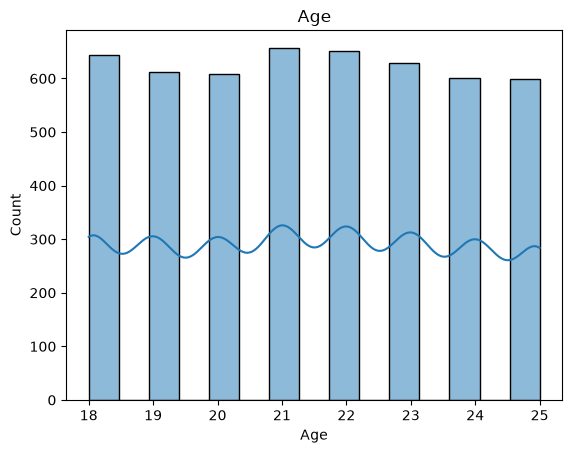

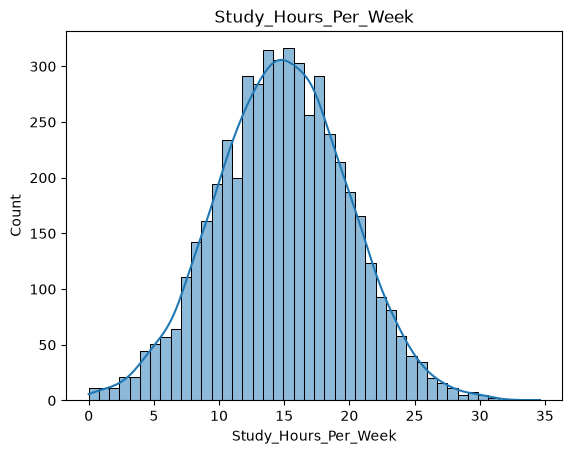

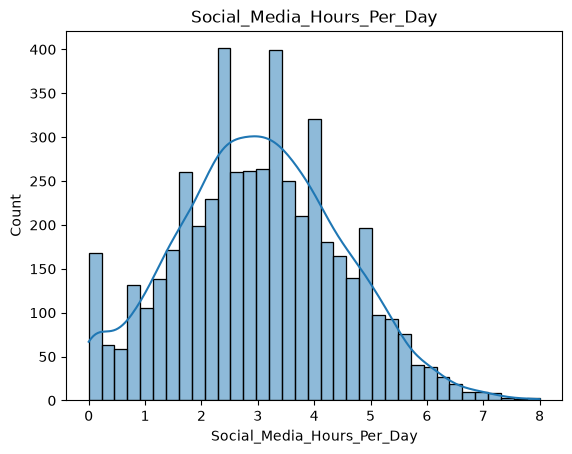

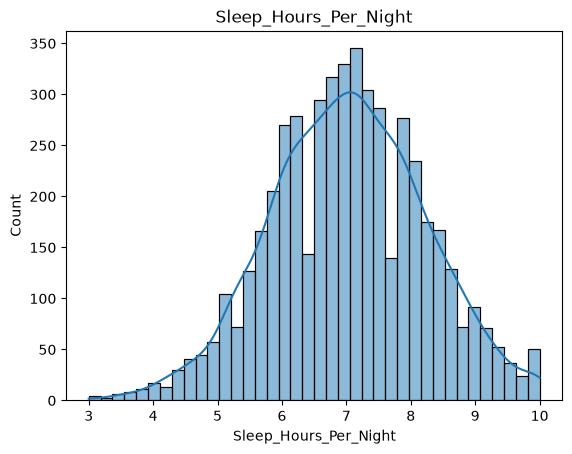

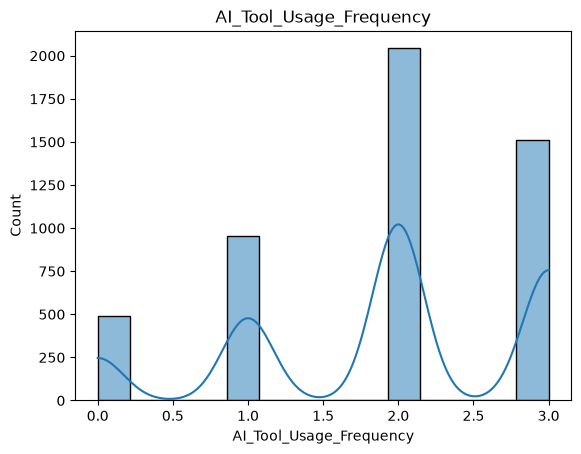

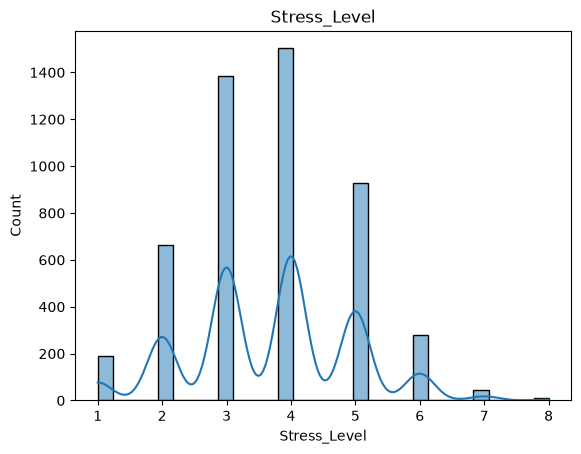

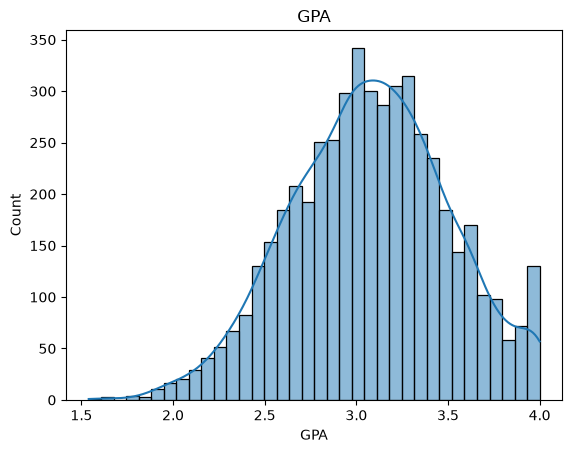

In [14]:
for col in data.columns:
    sns.histplot(data[col]  , kde=True )
    plt.title(col)
    plt.show()

Note <br>
Weight column --> maybe try a make two distribution from Weight Feature <br>
Body_Temp maybe this Feature have a bais <br>

## Split data
we will split data to 3 times  <br>
Train ---> dev ---> test <br>
Step 1 : train all models in Train-Set <br>
then <br> 
Step 2 : Validation all models in dev-Set <br> 
if model passed ---> compares model with others <br>
else remove it 

In [15]:
X = data.drop(columns= ["GPA"] )
y = data["GPA"]

In [16]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.3)

In [17]:
print(f"length of X_train ---> {len(X_train)}")
print(f"length of X_test ---> {len(X_test)}")

length of X_train ---> 3500
length of X_test ---> 1500


## Data Pipeline

In [22]:
import mlflow
from sklearn.pipeline import Pipeline , make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler , OneHotEncoder 
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

In [ ]:
num_pipeline = make_pipeline( StandardScaler() )
num_columns = X.columns

processor = ColumnTransformer(transformers=[
    ( "num pipeline", num_pipeline , num_columns) , 
])

Baseline = Pipeline( [ ("Preprocessing" , processor ) , ("Baseline" , LinearRegression()) ] )
Baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Baseline', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num pipeline', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the 

In [24]:

def train_baseline( X , y ):
    Baseline.fit(X , y)   
    return Baseline


def baseline_pipeline(X , y):
    train_baseline(X , y)

In [25]:
Baseline.fit(X_train , y_train)
Baseline.score(X_train , y_train)

0.554690495991935

In [32]:
Baseline.score(X_test , y_test)

0.540586247895194

In [2]:
from sklearn.tree import DecisionTreeRegressor


In [36]:
DTree_basic = DecisionTreeRegressor(
    max_depth=500 ,
    random_state=42 ,
    min_samples_split=5 , 
    splitter='best' ,
    ccp_alpha=0.0000001 ,

)
DTree_basic.fit(X_train , y_train)
DTree_basic.score(X_train , y_train)

0.9369443944630488

In [ ]:
DTree_basic.get_params

In [37]:
DTree_basic.score(X_test , y_test)

0.03663520397700937

In [3]:
X_train = pd.read_csv(r"\Challenges\mlops-project\src\data\processed\X_train_proced.csv").drop(columns=['Unnamed: 0'])
y_train = pd.read_csv(r"\Challenges\mlops-project\src\data\processed\y_train.csv").drop(columns=['Unnamed: 0'])

X_test = pd.read_csv(r"\Challenges\mlops-project\src\data\processed\X_test_proced.csv").drop(columns=['Unnamed: 0'])
y_test = pd.read_csv(r"\Challenges\mlops-project\src\data\processed\y_test.csv").drop(columns=['Unnamed: 0'])

In [8]:
from sklearn.ensemble import GradientBoostingRegressor

In [9]:
model = GradientBoostingRegressor()



In [15]:
y_train

,Unnamed: 0,GPA
0,2429,2.93
1,243,3.49
2,2060,2.71
3,3857,2.82
4,2861,3.04
...,...,...
3995,2910,2.98
3996,1830,3.09
3997,3217,2.68
3998,1948,2.95


In [16]:
X_train

,Unnamed: 0,Age,Study_Hours_Per_Week,Social_Media_Hours_Per_Day,Sleep_Hours_Per_Night,AI_Tool_Usage_Frequency,Stress_Level
0,2429,-0.656813,0.853777,1.558376,1.126283,0.093503,0.276770
1,243,-1.539330,0.515208,0.124083,0.711690,1.156037,1.083681
2,2060,-1.539330,-1.814946,-1.105310,-0.946682,0.093503,-1.337051
3,3857,-0.656813,-0.221678,1.763274,0.711690,0.093503,-0.530140
4,2861,1.549479,0.017312,-0.490613,0.462935,-0.969031,0.276770
...,...,...,...,...,...,...,...
3995,2910,1.549479,-1.197555,-0.354014,0.048342,0.093503,-1.337051
3996,1830,-1.098072,0.296134,0.055784,0.877527,1.156037,0.276770
3997,3217,1.549479,0.057144,1.148578,1.292120,-2.031566,0.276770
3998,1948,-0.215555,-1.376797,-0.900411,-0.863763,1.156037,0.276770


In [18]:
model.fit(X_train , y_train)
model.score(X_train , y_train)

d:\Challenges\mlops-project\.venv\Lib\site-packages\sklearn\ensemble\_gb.py:691: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


0.6032696143033401

In [19]:
model.score(X_test , y_test)

0.4934977983202631

In [1]:
import data_profiling 

In [13]:
profile = data_profiling.ProfileReport(
    data,
    title="Data Profile",
)

profile.to_file("data_profile.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 7/7 [00:00<00:00, 19573.42it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [21]:
abs(data[['GPA']].corrwith(data['Age']).to_list()[0])

0.011950549362950737

In [24]:
lis = data.columns.to_list()

In [25]:
lis.remove('Age')

In [26]:
lis

['Study_Hours_Per_Week',
 'Social_Media_Hours_Per_Day',
 'Sleep_Hours_Per_Night',
 'AI_Tool_Usage_Frequency',
 'Stress_Level',
 'GPA']